In [1]:
# =============================================================================
# SETUP CELL — standardized helpers: split / seed / device / timing / artifacts
# =============================================================================
import os, json, math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# ------------------------- global configuration -----------------------------
SEED           = 42
DATASET        = "mnist"          # "mnist" | "fashionmnist"
BATCH_SIZE     = 128
VAL_FRACTION   = 0.10
EPOCHS_CLS_MAX = 30               # classifier training cap
ACC_TARGET     = 0.88             # required test accuracy
LR_CLS         = 1e-3
EPOCHS_DEC_MAX = 40               # frozen-latent decoder training cap
LR_DEC         = 1e-3
H1, H2         = 256, 64          # tiered MLP hidden dims (784 -> 256 -> 64 -> 10)
ART            = "artifacts_mlp_gen_proof"
DEVICE         = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for sub in ("weights", "latents", "grids", "metrics", "data"):
    os.makedirs(os.path.join(ART, sub), exist_ok=True)

# ------------------------------- seed ---------------------------------------
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# ------------------------------- timing -------------------------------------
_TIMER_LOG = {}

class stage_timer:
    """Context manager: re-seeds the stage and logs wall-clock runtime."""
    def __init__(self, name: str):
        self.name = name
    def __enter__(self):
        set_seed(SEED)
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        dt = time.perf_counter() - self.t0
        _TIMER_LOG[self.name] = _TIMER_LOG.get(self.name, 0.0) + dt
        print(f"[timer] {self.name}: {dt:.2f}s (cumulative {_TIMER_LOG[self.name]:.2f}s)")

def save_timing() -> str:
    return save_json(_TIMER_LOG, os.path.join("metrics", "timing_log.json"))

# --------------------------- artifact saving --------------------------------
def save_tensor(t, name: str) -> str:
    path = os.path.join(ART, name)
    torch.save(t.detach().cpu() if torch.is_tensor(t) else t, path)
    return path

def save_json(obj, name: str) -> str:
    path = os.path.join(ART, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
    return path

def save_fig(fig, name: str) -> str:
    path = os.path.join(ART, "grids", name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

def render_grid(imgs, title: str, nrow: int = 10, fname: str = None):
    """imgs: (N,1,H,W) in [0,1]. Renders, optionally saves, shows."""
    grid = make_grid(imgs.detach().cpu().clamp(0, 1), nrow=nrow, padding=2)
    fig = plt.figure(figsize=(nrow * 1.2, 1.25 * math.ceil(len(imgs) / nrow) + 0.8))
    plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)), cmap="gray")
    plt.title(title)
    plt.axis("off")
    if fname:
        print("[saved]", save_fig(fig, fname))
    plt.show()

# --------------------------- standardized split ------------------------------
def build_dataloaders(dataset: str = DATASET, batch_size: int = BATCH_SIZE):
    tfm = transforms.ToTensor()  # pixels scaled to [0,1], no normalization
    root = os.path.join(ART, "data")
    cls = torchvision.datasets.MNIST if dataset == "mnist" else torchvision.datasets.FashionMNIST
    train_full = cls(root, train=True, download=True, transform=tfm)
    test_ds    = cls(root, train=False, download=True, transform=tfm)
    n_val = int(VAL_FRACTION * len(train_full))
    g = torch.Generator().manual_seed(SEED)
    idx = torch.randperm(len(train_full), generator=g).tolist()
    val_ds, trn_ds = Subset(train_full, idx[:n_val]), Subset(train_full, idx[n_val:])
    mk = lambda ds, sh: DataLoader(ds, batch_size=batch_size, shuffle=sh, num_workers=0)
    return mk(trn_ds, True), mk(val_ds, False), mk(test_ds, False)

# ------------------------------ initialization -------------------------------
set_seed(SEED)
train_loader, val_loader, test_loader = build_dataloaders()

xb, yb = next(iter(train_loader))
INPUT_DIM   = int(xb.view(xb.size(0), -1).shape[1])
IMG_SHAPE   = tuple(xb.shape[1:])
NUM_CLASSES = int(len(torch.unique(yb)) if len(torch.unique(yb)) > 1 else 10)
NUM_CLASSES = 10 if NUM_CLASSES < 10 else NUM_CLASSES

print(f"device        : {DEVICE}")
print(f"dataset       : {DATASET}")
print(f"split sizes   : train={len(train_loader.dataset)}  val={len(val_loader.dataset)}  test={len(test_loader.dataset)}")
print(f"input dim     : {INPUT_DIM}  img shape: {IMG_SHAPE}  classes: {NUM_CLASSES}")
print(f"architecture  : {INPUT_DIM} -> {H1} -> {H2} -> {NUM_CLASSES}")


device        : cpu
dataset       : mnist
split sizes   : train=54000  val=6000  test=10000
input dim     : 784  img shape: (1, 28, 28)  classes: 10
architecture  : 784 -> 256 -> 64 -> 10


In [2]:
# =============================================================================
# STEP 1 — Train tiered MLP classifier (784 -> 256 -> 64 -> 10) to >= 88% test acc
#          Save W1..W3 (+biases) and extract latent z_MLP in R^64 (pre-logit)
# =============================================================================
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=INPUT_DIM, h1=H1, h2=H2, n_classes=NUM_CLASSES):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.fc3 = nn.Linear(h2, n_classes)
    def features(self, x):
        x = x.view(x.size(0), -1)
        return F.relu(self.fc2(F.relu(self.fc1(x))))   # z_MLP in R^64, before final layer
    def forward(self, x):
        return self.fc3(self.features(x))

@torch.no_grad()
def evaluate_accuracy(model, loader) -> float:
    model.eval()
    correct = total = 0
    for xb, yb in loader:
        pred = model(xb.to(DEVICE)).argmax(dim=1).cpu()
        correct += (pred == yb).sum().item()
        total   += yb.numel()
    return correct / total

@torch.no_grad()
def extract_latents(model, loader):
    model.eval()
    zs, ys = [], []
    for xb, yb in loader:
        zs.append(model.features(xb.to(DEVICE)).cpu())
        ys.append(yb)
    return torch.cat(zs), torch.cat(ys)

set_seed(SEED)
clf = MLPClassifier().to(DEVICE)
opt_cls  = torch.optim.Adam(clf.parameters(), lr=LR_CLS)
crit_cls = nn.CrossEntropyLoss()

cls_history = []
with stage_timer("step1_train_mlp_classifier"):
    for epoch in range(1, EPOCHS_CLS_MAX + 1):
        clf.train()
        run_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt_cls.zero_grad()
            loss = crit_cls(clf(xb), yb)
            loss.backward()
            opt_cls.step()
            run_loss += loss.item() * yb.numel()
            seen     += yb.numel()
        train_loss = run_loss / seen
        val_acc = evaluate_accuracy(clf, val_loader)
        test_acc = evaluate_accuracy(clf, test_loader)
        cls_history.append({"epoch": epoch, "train_loss": train_loss,
                            "val_acc": val_acc, "test_acc": test_acc})
        print(f"[step1] epoch {epoch:02d} | train_loss={train_loss:.4f} "
              f"| val_acc={val_acc:.4f} | test_acc={test_acc:.4f}")
        if test_acc >= ACC_TARGET:
            print(f"[step1] target test accuracy {ACC_TARGET:.2%} reached.")
            break

# ---- save trained weight matrices and biases ----
with torch.no_grad():
    W1, b1 = clf.fc1.weight.detach().clone(), clf.fc1.bias.detach().clone()   # (256,784),(256,)
    W2, b2 = clf.fc2.weight.detach().clone(), clf.fc2.bias.detach().clone()   # (64,256),(64,)
    W3, b3 = clf.fc3.weight.detach().clone(), clf.fc3.bias.detach().clone()   # (10,64),(10,)

print("[saved]", save_tensor({"W1": W1, "b1": b1, "W2": W2, "b2": b2,
                              "W3": W3, "b3": b3}, os.path.join("weights", "mlp_classifier_weights.pt")))
print("[saved]", save_tensor(clf.state_dict(), os.path.join("weights", "mlp_classifier_statedict.pt")))

# ---- extract latent representations z_MLP in R^64 ----
z_train, y_train_lat = extract_latents(clf, train_loader)
z_val,   y_val_lat   = extract_latents(clf, val_loader)
z_test,  y_test_lat  = extract_latents(clf, test_loader)

print("[saved]", save_tensor(z_train, os.path.join("latents", "z_mlp_train.pt")))
print("[saved]", save_tensor(z_val,   os.path.join("latents", "z_mlp_val.pt")))
print("[saved]", save_tensor(z_test,  os.path.join("latents", "z_mlp_test.pt")))

step1_metrics = {
    "final_test_acc": cls_history[-1]["test_acc"],
    "final_val_acc": cls_history[-1]["val_acc"],
    "epochs_trained": len(cls_history),
    "acc_target": ACC_TARGET,
    "target_met": cls_history[-1]["test_acc"] >= ACC_TARGET,
    "z_dim": int(z_test.shape[1]),
    "history": cls_history,
}
print("[saved]", save_json(step1_metrics, os.path.join("metrics", "step1_classifier.json")))
print("[saved]", save_timing())
print(f"[step1] summary: test_acc={step1_metrics['final_test_acc']:.4f} "
      f"after {step1_metrics['epochs_trained']} epochs | z_MLP dim={step1_metrics['z_dim']}")


[step1] epoch 01 | train_loss=0.3876 | val_acc=0.9408 | test_acc=0.9450
[step1] target test accuracy 88.00% reached.
[timer] step1_train_mlp_classifier: 9.12s (cumulative 9.12s)
[saved] artifacts_mlp_gen_proof\weights\mlp_classifier_weights.pt
[saved] artifacts_mlp_gen_proof\weights\mlp_classifier_statedict.pt
[saved] artifacts_mlp_gen_proof\latents\z_mlp_train.pt
[saved] artifacts_mlp_gen_proof\latents\z_mlp_val.pt
[saved] artifacts_mlp_gen_proof\latents\z_mlp_test.pt
[saved] artifacts_mlp_gen_proof\metrics\step1_classifier.json
[saved] artifacts_mlp_gen_proof\metrics\timing_log.json
[step1] summary: test_acc=0.9450 after 1 epochs | z_MLP dim=64


[step2] class prototypes y_c: (10, 10) -> x_hat: (10, 1, 28, 28)
[saved] artifacts_mlp_gen_proof\grids\step2_class_prototypes.pt
[saved] artifacts_mlp_gen_proof\grids\step2_class_prototypes.png


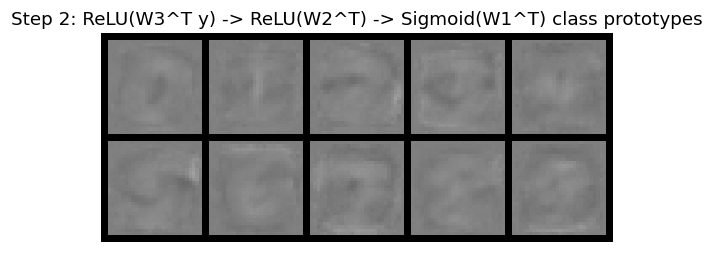

In [3]:
# =============================================================================
# STEP 2 — Top-down weight transposition from one-hot class vectors (no training)
#          z_hat  = ReLU(W3^T y_c);  h1_hat = ReLU(W2^T z_hat);  x_hat = Sigmoid(W1^T h1_hat)
# =============================================================================
y_c = F.one_hot(torch.arange(NUM_CLASSES), num_classes=NUM_CLASSES).float().to(DEVICE)

with torch.no_grad():
    z_hat_step2  = torch.relu(y_c @ W3)     # W3^T y_c : R^10 -> R^64   (row-vector form)
    h1_hat_step2 = torch.relu(z_hat_step2 @ W2)   # W2^T z_hat : R^64 -> R^256
    x_hat_step2  = torch.sigmoid(h1_hat_step2 @ W1)   # W1^T h1_hat : R^256 -> R^784

x_hat_step2_img = x_hat_step2.view(-1, *IMG_SHAPE).cpu()
print(f"[step2] class prototypes y_c: {tuple(y_c.shape)} -> x_hat: {tuple(x_hat_step2_img.shape)}")
print("[saved]", save_tensor(x_hat_step2_img, os.path.join("grids", "step2_class_prototypes.pt")))
render_grid(x_hat_step2_img, "Step 2: ReLU(W3^T y) -> ReLU(W2^T) -> Sigmoid(W1^T) class prototypes",
            nrow=5, fname="step2_class_prototypes.png")
save_json({"note": "zero-extra-training transposed-weight class prototypes",
           "shape": list(x_hat_step2_img.shape)}, os.path.join("metrics", "step2_prototypes.json"))


[step3] z_MLP (64,) -> x_hat (10, 1, 28, 28)
[saved] artifacts_mlp_gen_proof\grids\step3_side_by_side.pt
[saved] artifacts_mlp_gen_proof\grids\step3_side_by_side.png
[step3] MSE(transpose projection, ground truth) = 0.325730


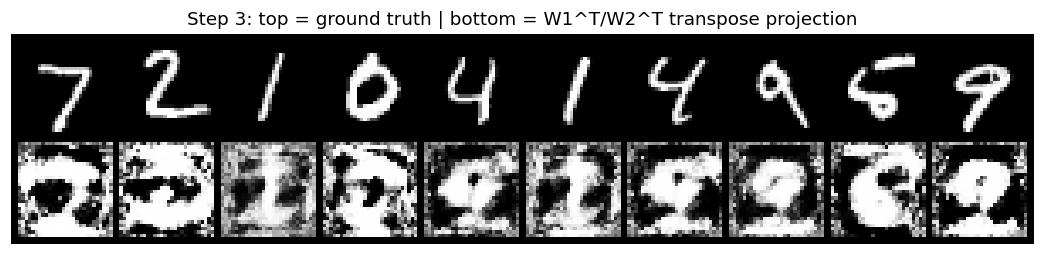

In [4]:
# =============================================================================
# STEP 3 — Latent transpose projection of REAL test images back to pixel space
#          x_hat = Sigmoid(W1^T ReLU(W2^T z_MLP)); side-by-side vs ground truth
# =============================================================================
N_SHOW = 10
with torch.no_grad():
    x_hat_step3 = torch.sigmoid(torch.relu(z_test[:N_SHOW].to(DEVICE) @ W2) @ W1)

x_hat_step3_img = x_hat_step3.view(-1, *IMG_SHAPE).cpu()
x_true_step3    = next(iter(test_loader))[0][:N_SHOW]

print(f"[step3] z_MLP {tuple(z_test.shape[1:])} -> x_hat {tuple(x_hat_step3_img.shape)}")
comparison = torch.cat([x_true_step3, x_hat_step3_img], dim=0)
print("[saved]", save_tensor(comparison, os.path.join("grids", "step3_side_by_side.pt")))
render_grid(comparison, "Step 3: top = ground truth | bottom = W1^T/W2^T transpose projection",
            nrow=N_SHOW, fname="step3_side_by_side.png")

mse_step3 = F.mse_loss(x_hat_step3_img, x_true_step3).item()
save_json({"test_mse_transpose_projection": mse_step3, "n_pairs": N_SHOW},
          os.path.join("metrics", "step3_projection.json"))
print(f"[step3] MSE(transpose projection, ground truth) = {mse_step3:.6f}")


[step4] epoch 01 | train_mse=0.070682 | test_mse=0.068546 | test_psnr=11.79dB | test_ssim=0.1269
[step4] epoch 02 | train_mse=0.067902 | test_mse=0.068338 | test_psnr=11.82dB | test_ssim=0.1272
[step4] epoch 03 | train_mse=0.067646 | test_mse=0.068052 | test_psnr=11.83dB | test_ssim=0.1217
[step4] epoch 04 | train_mse=0.067483 | test_mse=0.068022 | test_psnr=11.83dB | test_ssim=0.1164
[step4] epoch 05 | train_mse=0.067406 | test_mse=0.068247 | test_psnr=11.84dB | test_ssim=0.1234
[step4] epoch 06 | train_mse=0.067364 | test_mse=0.067975 | test_psnr=11.84dB | test_ssim=0.1194
[step4] epoch 07 | train_mse=0.067349 | test_mse=0.067851 | test_psnr=11.85dB | test_ssim=0.1225
[step4] epoch 08 | train_mse=0.067340 | test_mse=0.067551 | test_psnr=11.85dB | test_ssim=0.1148
[step4] epoch 09 | train_mse=0.067316 | test_mse=0.067852 | test_psnr=11.83dB | test_ssim=0.1150
[step4] epoch 10 | train_mse=0.067306 | test_mse=0.067684 | test_psnr=11.86dB | test_ssim=0.1191
[step4] epoch 11 | train_mse=0

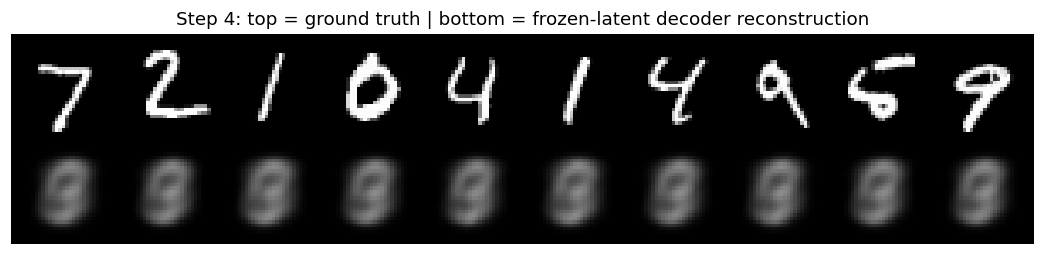

In [5]:
# =============================================================================
# STEP 4 — Frozen-latent MLP decoder (64 -> 256 -> 784), MSE loss
#          Metrics: Test MSE, Test PSNR, Test SSIM (+ artifacts)
# =============================================================================
for p in clf.parameters():
    p.requires_grad = False
clf.eval()
for xb, _ in train_loader:      # sanity check: no classifier grad flows
    break

@torch.no_grad()
def collect_flat_images(loader):
    xs, ys = [], []
    for xb, yb in loader:
        xs.append(xb.view(xb.size(0), -1))
        ys.append(yb)
    return torch.cat(xs), torch.cat(ys)

X_train_flat, _ = collect_flat_images(train_loader)
X_test_flat,  _ = collect_flat_images(test_loader)

class FrozenLatentDecoder(nn.Module):
    def __init__(self, z_dim=H2, hid=H1, out_dim=INPUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, hid), nn.ReLU(),
            nn.Linear(hid, out_dim), nn.Sigmoid(),
        )
    def forward(self, z):
        return self.net(z)

def _gaussian_kernel_2d(k=11, sigma=1.5):
    ax = torch.arange(k, dtype=torch.float32) - (k - 1) / 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return torch.outer(g, g)

@torch.no_grad()
def ssim_per_image(pred, target, k=11, sigma=1.5, C1=0.01 ** 2, C2=0.03 ** 2):
    """pred/target: (N,1,H,W) in [0,1]. Returns (N,) SSIM."""
    kern = _gaussian_kernel_2d(k, sigma).to(pred.device).view(1, 1, k, k)
    mu_p, mu_t = F.conv2d(pred, kern), F.conv2d(target, kern)
    var_p = F.conv2d(pred * pred, kern) - mu_p ** 2
    var_t = F.conv2d(target * target, kern) - mu_t ** 2
    cov   = F.conv2d(pred * target, kern) - mu_p * mu_t
    num = (2 * mu_p * mu_t + C1) * (2 * cov + C2)
    den = (mu_p ** 2 + mu_t ** 2 + C1) * (var_p + var_t + C2)
    return ((num / den).flatten(1)).mean(1)

@torch.no_grad()
def reconstruction_metrics(decoder, z, x_flat):
    decoder.eval()
    x_rec = decoder(z.to(next(decoder.parameters()).device)).cpu()
    mse_vec = F.mse_loss(x_rec, x_flat, reduction="none").mean(dim=1)
    psnr_vec = 10.0 * torch.log10(1.0 / mse_vec)
    ssim_vec = ssim_per_image(x_rec.view(-1, *IMG_SHAPE), x_flat.view(-1, *IMG_SHAPE))
    return {"test_mse": mse_vec.mean().item(),
            "test_psnr_db": psnr_vec.mean().item(),
            "test_ssim": ssim_vec.mean().item()}, x_rec

set_seed(SEED)
decoder = FrozenLatentDecoder().to(DEVICE)
opt_dec = torch.optim.Adam(decoder.parameters(), lr=LR_DEC)
crit_dec = nn.MSELoss()

dec_train_ds = TensorDataset(z_train, X_train_flat)
dec_train_loader = DataLoader(dec_train_ds, batch_size=BATCH_SIZE, shuffle=True)
dec_test_ds  = TensorDataset(z_test, X_test_flat)
dec_test_loader  = DataLoader(dec_test_ds, batch_size=BATCH_SIZE, shuffle=False)

dec_history = []
with stage_timer("step4_train_frozen_latent_decoder"):
    for epoch in range(1, EPOCHS_DEC_MAX + 1):
        decoder.train()
        run_loss, seen = 0.0, 0
        for zb, xb in dec_train_loader:
            zb, xb = zb.to(DEVICE), xb.to(DEVICE)
            opt_dec.zero_grad()
            loss = crit_dec(decoder(zb), xb)
            loss.backward()
            opt_dec.step()
            run_loss += loss.item() * zb.size(0)
            seen     += zb.size(0)
        train_mse = run_loss / seen
        test_metrics, _ = reconstruction_metrics(decoder, z_test, X_test_flat)
        dec_history.append({"epoch": epoch, "train_mse": train_mse, **test_metrics})
        print(f"[step4] epoch {epoch:02d} | train_mse={train_mse:.6f} "
              f"| test_mse={test_metrics['test_mse']:.6f} "
              f"| test_psnr={test_metrics['test_psnr_db']:.2f}dB "
              f"| test_ssim={test_metrics['test_ssim']:.4f}")

step4_metrics, x_rec_test = reconstruction_metrics(decoder, z_test, X_test_flat)
step4_metrics["epochs_trained"] = len(dec_history)
step4_metrics["classifier_frozen"] = all(not p.requires_grad for p in clf.parameters())
step4_metrics["history"] = dec_history

print("[saved]", save_tensor(decoder.state_dict(), os.path.join("weights", "frozen_latent_decoder_statedict.pt")))
print("[saved]", save_tensor(x_rec_test.view(-1, *IMG_SHAPE), os.path.join("grids", "step4_test_reconstructions.pt")))
print("[saved]", save_json(step4_metrics, os.path.join("metrics", "step4_frozen_decoder.json")))
print("[saved]", save_timing())
print(f"[step4] summary: Test MSE={step4_metrics['test_mse']:.6f} "
      f"| PSNR={step4_metrics['test_psnr_db']:.2f}dB "
      f"| SSIM={step4_metrics['test_ssim']:.4f} "
      f"| classifier_frozen={step4_metrics['classifier_frozen']}")

render_grid(torch.cat([X_test_flat[:N_SHOW].view(-1, *IMG_SHAPE),
                       x_rec_test[:N_SHOW].view(-1, *IMG_SHAPE)], dim=0),
            "Step 4: top = ground truth | bottom = frozen-latent decoder reconstruction",
            nrow=N_SHOW, fname="step4_reconstructions.png")


[saved] artifacts_mlp_gen_proof\latents\mu_z.pt
[saved] artifacts_mlp_gen_proof\latents\sigma_z.pt
[timer] step5_random_latent_sampling: 0.00s (cumulative 0.00s)
[step5] sampled z_rand (25, 64) -> generated (25, 1, 28, 28)
[saved] artifacts_mlp_gen_proof\latents\z_rand_sample.pt
[saved] artifacts_mlp_gen_proof\grids\step5_generated_samples.pt
[saved] artifacts_mlp_gen_proof\grids\step5_generated_samples.png
[saved] artifacts_mlp_gen_proof\metrics\run_summary.json
[saved] artifacts_mlp_gen_proof\metrics\timing_log.json
[done] run summary: {
  "step1_final_test_acc": 0.945,
  "step4_test_mse": 0.06793135404586792,
  "step4_test_psnr_db": 11.843708992004395,
  "step4_test_ssim": 0.11954247951507568,
  "step3_transpose_projection_mse": 0.3257300555706024,
  "n_generated_samples": 25,
  "artifacts_dir": "artifacts_mlp_gen_proof"
}


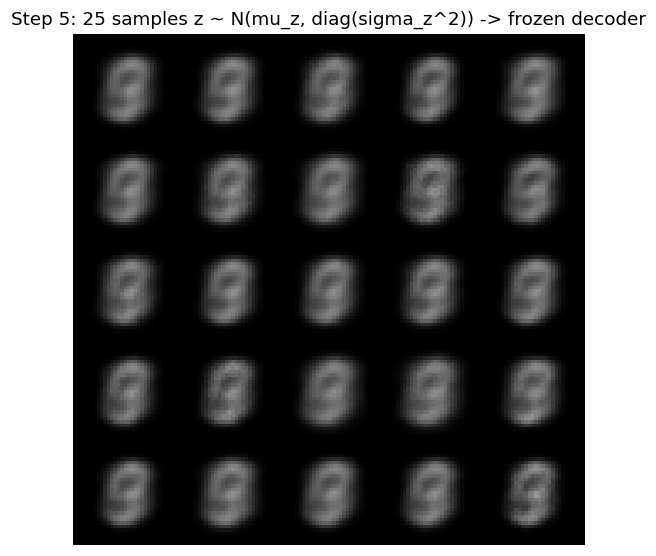

In [6]:
# =============================================================================
# STEP 5 — Random sampling on the MLP latent space
#          mu_z, sigma_z from test latents; z_rand ~ N(mu_z, diag(sigma_z^2));
#          decode z_rand with the Step-4 frozen-latent decoder
# =============================================================================
N_SAMPLES = 25

mu_z    = z_test.mean(dim=0)
sigma_z = z_test.std(dim=0)
print(f"[saved]", save_tensor(mu_z,    os.path.join("latents", "mu_z.pt")))
print(f"[saved]", save_tensor(sigma_z, os.path.join("latents", "sigma_z.pt")))

set_seed(SEED)
with stage_timer("step5_random_latent_sampling"):
    with torch.no_grad():
        z_rand = mu_z + torch.randn(N_SAMPLES, z_test.shape[1]) * sigma_z     # N(mu_z, diag(sigma_z^2))
        x_rand = decoder(z_rand.to(DEVICE)).cpu()

x_rand_img = x_rand.view(-1, *IMG_SHAPE)
print(f"[step5] sampled z_rand {tuple(z_rand.shape)} -> generated {tuple(x_rand_img.shape)}")
print("[saved]", save_tensor(z_rand,    os.path.join("latents", "z_rand_sample.pt")))
print("[saved]", save_tensor(x_rand_img, os.path.join("grids", "step5_generated_samples.pt")))
render_grid(x_rand_img, f"Step 5: {N_SAMPLES} samples z ~ N(mu_z, diag(sigma_z^2)) -> frozen decoder",
            nrow=5, fname="step5_generated_samples.png")

summary = {
    "step1_final_test_acc": step1_metrics["final_test_acc"],
    "step4_test_mse": step4_metrics["test_mse"],
    "step4_test_psnr_db": step4_metrics["test_psnr_db"],
    "step4_test_ssim": step4_metrics["test_ssim"],
    "step3_transpose_projection_mse": mse_step3,
    "n_generated_samples": N_SAMPLES,
    "artifacts_dir": ART,
}
print("[saved]", save_json(summary, os.path.join("metrics", "run_summary.json")))
print("[saved]", save_timing())
print("[done] run summary:", json.dumps(summary, indent=2))
